# Eigenvectors in Photonics: From Two Coupled Waveguides to Quantum Walks

**Start with high-school physics.** Hang two identical pendulums from a slack string
and pull one aside. Its swinging slowly passes to the other pendulum, then comes
back. Two optical waveguides placed close together do the same thing with light.
The light "leaks" through the evanescent field from one guide to the other and back.

**Then precalculus.** The fraction of light in the second guide is $\sin^2(\kappa z)$,
just a trig function of distance.

**Then linear algebra.** Why $\sin^2$? Because the pair has two special patterns,
**eigenvectors**, that travel without changing shape. Every other launch is a mix
of them. That idea scales to arrays of hundreds of waveguides and leads straight to
quantum information science.

| § | level | result |
|---|---|---|
| 1 | precalculus / HS physics | two guides: power sloshes as $\sin^2(\kappa z)$ |
| 2 | linear algebra | supermodes = eigenvectors, proven for *any* N with SymPy |
| 3 | loops over N | eigenvalue bands, and the patterns inside |
| 4 | special functions | infinite array: light spreads as Bessel functions $J_n(2\kappa z)^2$ |
| 5 | quantum information | engineered couplings → **perfect state transfer** |
| 6 | quantum optics | two photons on a coupler → **Hong–Ou–Mandel dip** |

Module: [`dgs/waveguide_array_eigen.py`](../dgs/waveguide_array_eigen.py).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, Math
from dgs.waveguide_array_eigen import (
    coupling_matrix, propagate_eig, propagate_expm, two_guide_symbolic,
    uniform_array_eigen_check, uniform_array_eigen_numeric, bessel_identity_check,
    discrete_diffraction, rms_width_infinite, pst_couplings, pst_eigenvalues_symbolic,
    transfer_fidelity, coincidence_probability_symbolic, coincidence_distinguishable_symbolic,
    mc_coincidences,
)

# 1. Two waveguides: the coupled-pendulum picture

With amplitudes $a_1, a_2$ in the two guides, coupled-mode theory gives

$$-i\frac{d}{dz}\begin{pmatrix}a_1\\a_2\end{pmatrix} = \underbrace{\begin{pmatrix}\beta & \kappa\\ \kappa & \beta\end{pmatrix}}_{H}\begin{pmatrix}a_1\\a_2\end{pmatrix}$$

SymPy finds the eigenvectors and the matrix exponential, then the power in guide 2
after launching into guide 1:

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

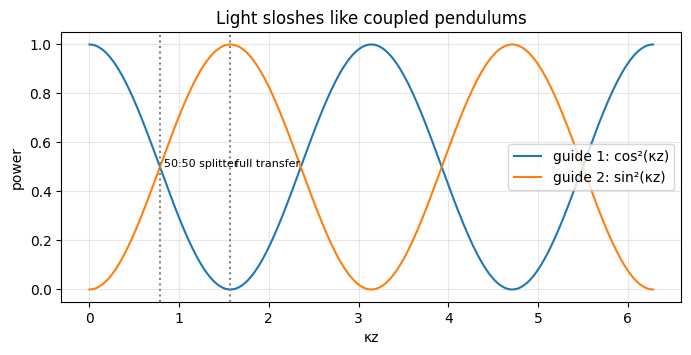

In [2]:
d = two_guide_symbolic()
for val, mult, vecs in d["eigenvects"]:
    display(Math(r"\lambda = " + sp.latex(val) + r",\quad v = " + sp.latex(vecs[0].T)))
display(Math(r"P_2(z) = " + sp.latex(d["P2"])))
kz = np.linspace(0, 2*np.pi, 400)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(kz, np.cos(kz)**2, label="guide 1: cos²(κz)"); ax.plot(kz, np.sin(kz)**2, label="guide 2: sin²(κz)")
for x, lab in ((np.pi/4, "50:50 splitter"), (np.pi/2, "full transfer")):
    ax.axvline(x, color="0.5", ls=":"); ax.text(x + 0.05, 0.5, lab, fontsize=8)
ax.set(xlabel="κz", ylabel="power", title="Light sloshes like coupled pendulums"); ax.legend(); ax.grid(alpha=0.3); plt.show()

**Why this works.** The symmetric pattern $(1,1)$ travels with propagation
constant $\beta+\kappa$, and the antisymmetric pattern $(1,-1)$ with $\beta-\kappa$.
Launching into guide 1 means $(1,0) = \tfrac12[(1,1)+(1,-1)]$. The two parts slowly
get out of phase, and when they're fully out of phase the sum is $(0,1)$: all the
light is in guide 2. A device length of $\kappa L = \pi/4$ makes a 50:50 beam
splitter, which is the building block of every Mach–Zehnder modulator.

# 2. N guides: proving the eigenvectors for every N

For a uniform array of $N$ guides, guess $v_n = \sin(n t)$. SymPy confirms that it
satisfies the eigenvalue equation at every interior guide:

In [3]:
display(Math(r"\kappa\,[\sin((n-1)t) + \sin((n+1)t)] - 2\kappa\cos t\,\sin(nt) \;=\; " + sp.latex(uniform_array_eigen_check())))

<IPython.core.display.Math object>

The edges require $v_0 = v_{N+1} = 0$, so $t = k\pi/(N+1)$. That gives

$$v_k(n) = \sin\frac{nk\pi}{N+1},\qquad \lambda_k = \beta + 2\kappa\cos\frac{k\pi}{N+1},\qquad k = 1,\dots,N$$

These are exactly the modes of a string fixed at both ends, the same math as the
standing waves in high-school physics. The loop below compares the formula with
NumPy's numerical eigen-solver for several N:

In [4]:
for N in (2, 3, 5, 10, 25):
    lam, V = uniform_array_eigen_numeric(N)
    l2, V2 = np.linalg.eigh(coupling_matrix(N))
    print(f"N = {N:2d}: eigenvalues match {np.allclose(lam, l2)},  eigenvectors match "
          f"{np.allclose(np.abs(V.T @ V2), np.eye(N), atol=1e-10)}")

N =  2: eigenvalues match True,  eigenvectors match True
N =  3: eigenvalues match True,  eigenvectors match True
N =  5: eigenvalues match True,  eigenvectors match True
N = 10: eigenvalues match True,  eigenvectors match True
N = 25: eigenvalues match True,  eigenvectors match True


# 3. Looping through N: from discrete levels to a band

As $N$ grows, the eigenvalues fill the interval $[\beta - 2\kappa,\ \beta + 2\kappa]$.
That's a **band**, the photonic analog of an energy band in a crystal (compare
`band_theory.py`).

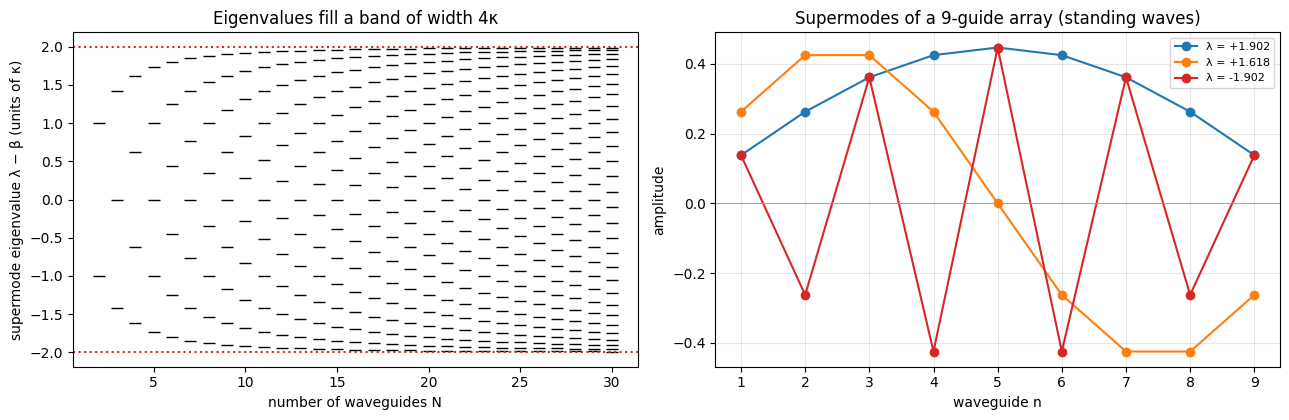

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for N in range(2, 31):
    lam, _ = uniform_array_eigen_numeric(N)
    axes[0].plot(np.full(N, N), lam, "k_", ms=8)
axes[0].axhline(2, color="C3", ls=":"); axes[0].axhline(-2, color="C3", ls=":")
axes[0].set(xlabel="number of waveguides N", ylabel="supermode eigenvalue λ − β (units of κ)",
            title="Eigenvalues fill a band of width 4κ")
N = 9; lam, V = uniform_array_eigen_numeric(N)
for j, col in zip((N-1, N-2, 0), ("C0", "C1", "C3")):
    axes[1].plot(np.arange(1, N+1), V[:, j], "o-", color=col, label=f"λ = {lam[j]:+.3f}")
axes[1].axhline(0, color="0.6", lw=0.6)
axes[1].set(xlabel="waveguide n", ylabel="amplitude", title=f"Supermodes of a {N}-guide array (standing waves)")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

# 4. An infinite array: discrete diffraction is a Bessel function

Launch light into one guide of a very large array. The exact solution is
$a_n(z) = i^nJ_n(2\kappa z)$ (SymPy checks it against the coupled-mode equation using
Bessel recurrences). Unlike ordinary diffraction, the light spreads as two
**ballistic lobes** at the edges, with rms width $\sqrt2\,\kappa z$ growing
*linearly*. A diffusive random walk grows only as $\sqrt z$.

SymPy residual of a_n = iⁿ J_n(2κz): 0


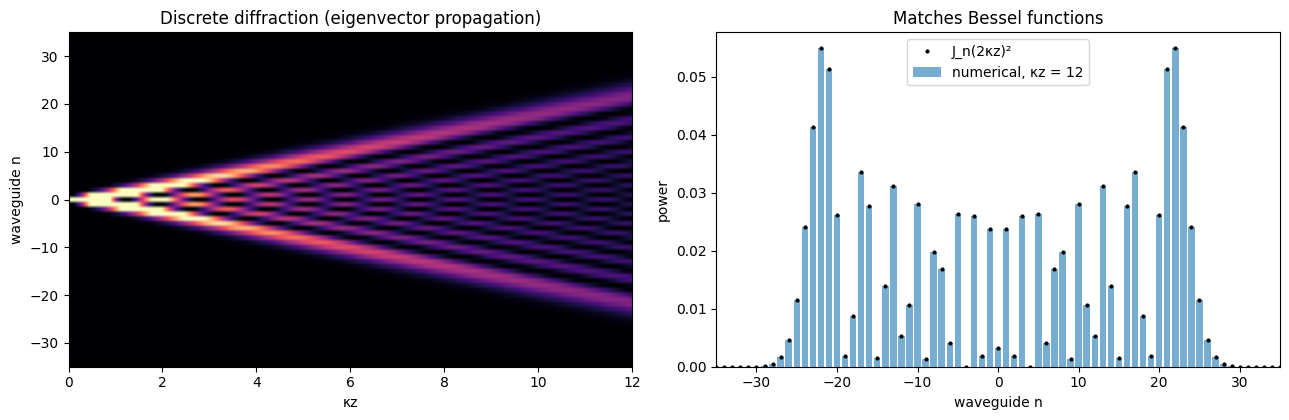

rms width at κz = 12: numerical 16.9706,  √2·κz = 16.9706
eigen-decomposition vs matrix exponential: 1.9063137060435736e-15


In [6]:
print("SymPy residual of a_n = iⁿ J_n(2κz):", bessel_identity_check())
N = 201; H = coupling_matrix(N); a0 = np.zeros(N); a0[100] = 1
zs = np.linspace(0, 12, 240)
I = np.array([np.abs(propagate_eig(H, a0, z))**2 for z in zs])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].imshow(I.T, aspect="auto", origin="lower", extent=[0, 12, -100, 100], cmap="magma", vmax=0.15)
axes[0].set(xlabel="κz", ylabel="waveguide n", ylim=(-35, 35), title="Discrete diffraction (eigenvector propagation)")
n = np.arange(N) - 100
axes[1].bar(n, I[-1], color="C0", alpha=0.6, label="numerical, κz = 12")
axes[1].plot(n, discrete_diffraction(n, 12), "k.", ms=4, label="J_n(2κz)²")
axes[1].set(xlim=(-35, 35), xlabel="waveguide n", ylabel="power", title="Matches Bessel functions")
axes[1].legend(); plt.tight_layout(); plt.show()
w = np.sqrt((I * n**2).sum(axis=1))
print(f"rms width at κz = 12: numerical {w[-1]:.4f},  √2·κz = {float(rms_width_infinite(12)):.4f}")
print("eigen-decomposition vs matrix exponential:", np.max(np.abs(propagate_eig(H, a0, 7) - propagate_expm(H, a0, 7))))

In quantum information science this is a **continuous-time quantum walk**. A single
photon in the array spreads quadratically faster than a classical random walker,
and that speed-up is what quantum-walk search algorithms exploit. Waveguide arrays
in glass and silicon are one of the main platforms for demonstrating it.

# 5. Perfect state transfer: engineering the eigenvalues

Can light be moved *perfectly* from guide 1 to guide $N$? In a uniform array, no.
The eigenvalues $2\kappa\cos(k\pi/(N+1))$ are unevenly spaced, so the supermodes
never all come back into phase. Choose the couplings
$\kappa_n = \kappa_0\sqrt{n(N-n)}$ instead, and SymPy shows the eigenvalues become
**equally spaced**:

N = 4: eigenvalues (units of κ0) = [-3, -1, 1, 3]
N = 5: eigenvalues (units of κ0) = [-4, -2, 0, 2, 4]
N = 6: eigenvalues (units of κ0) = [-5, -3, -1, 1, 3, 5]


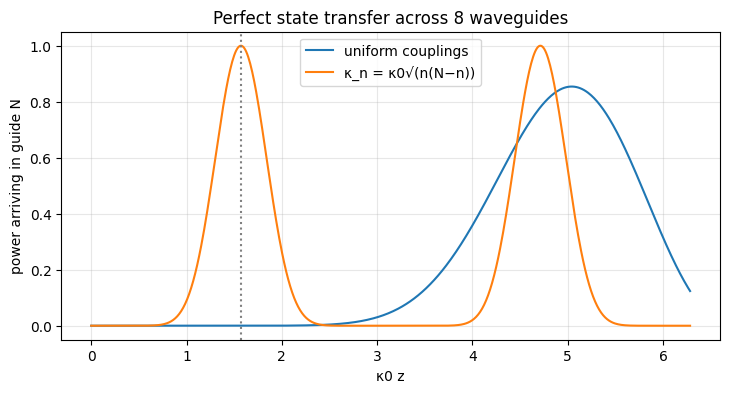

engineered: fidelity at z = π/2κ0 = 1.000000000000
uniform: best fidelity for z in [0, 30] = 0.8542


In [7]:
for N in (4, 5, 6):
    print(f"N = {N}: eigenvalues (units of κ0) = {pst_eigenvalues_symbolic(N)}")
fig, ax = plt.subplots(figsize=(8.5, 4))
N = 8; zs = np.linspace(0, 2*np.pi, 600)
ax.plot(zs, [transfer_fidelity(N, z) for z in zs], label="uniform couplings")
ax.plot(zs, [transfer_fidelity(N, z, pst_couplings(N)) for z in zs], label="κ_n = κ0√(n(N−n))")
ax.axvline(np.pi/2, color="0.5", ls=":")
ax.set(xlabel="κ0 z", ylabel="power arriving in guide N", title=f"Perfect state transfer across {N} waveguides")
ax.legend(); ax.grid(alpha=0.3); plt.show()
print(f"engineered: fidelity at z = π/2κ0 = {transfer_fidelity(N, np.pi/2, pst_couplings(N)):.12f}")
print(f"uniform: best fidelity for z in [0, 30] = {max(transfer_fidelity(N, z) for z in np.linspace(0, 30, 6001)):.4f}")

Equally spaced eigenvalues mean every supermode's phase $e^{i\lambda_kz}$ realigns at
the same distance. This is how quantum states, not just light intensity, can be
moved along a chain of qubits or waveguides with no loss of information.

# 6. Two photons: the Hong–Ou–Mandel dip

Send **one photon into each input** of a coupler. Quantum mechanics adds the
*amplitudes* for "both transmitted" and "both reflected", and the probability of one
photon leaving each output is $|\mathrm{perm}\,U|^2$ (a *permanent*, which is a
determinant without the minus signs). Classical particles add *probabilities*
instead:

<IPython.core.display.Math object>

<IPython.core.display.Math object>

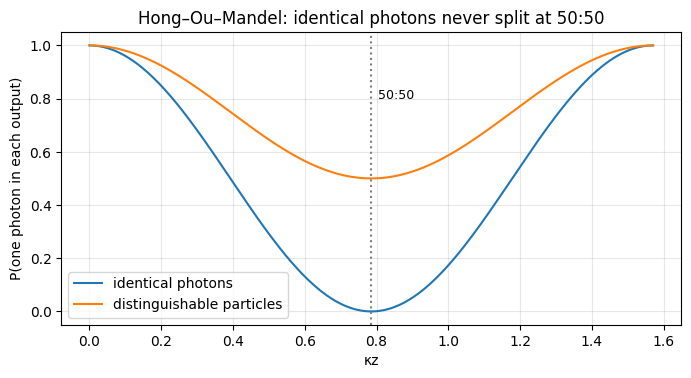

at 50:50 — identical photons: P = 0.000 (simulated 0.0000);  distinguishable: P = 0.500 (simulated 0.5010)


In [8]:
P, k, z = coincidence_probability_symbolic(); Pd, _, _ = coincidence_distinguishable_symbolic()
display(Math(r"P_\text{coinc}^\text{photons} = |U_{11}U_{22} + U_{12}U_{21}|^2 = " + sp.latex(P)))
display(Math(r"P_\text{coinc}^\text{classical} = |U_{11}U_{22}|^2 + |U_{12}U_{21}|^2 = " + sp.latex(Pd)))
kz = np.linspace(0, np.pi/2, 300)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(kz, np.cos(2*kz)**2, label="identical photons"); ax.plot(kz, np.cos(kz)**4 + np.sin(kz)**4, label="distinguishable particles")
ax.axvline(np.pi/4, color="0.5", ls=":"); ax.text(np.pi/4 + 0.02, 0.8, "50:50", fontsize=9)
ax.set(xlabel="κz", ylabel="P(one photon in each output)", title="Hong–Ou–Mandel: identical photons never split at 50:50")
ax.legend(); ax.grid(alpha=0.3); plt.show()
mc, p = mc_coincidences(np.pi/4); mcd, pd_ = mc_coincidences(np.pi/4, indistinguishable=False)
print(f"at 50:50 — identical photons: P = {p:.3f} (simulated {mc:.4f});  distinguishable: P = {pd_:.3f} (simulated {mcd:.4f})")

At the 50:50 point the two amplitudes cancel exactly, and both photons always
leave *together*. This is the Hong–Ou–Mandel effect (1987). It's how labs test
whether two photons are truly identical, and it's the basic interference step in
photonic quantum computing (boson sampling and linear-optical gates).

# Summary

| idea | SymPy | numerical check |
|---|---|---|
| two-guide transfer $\sin^2(\kappa z)$ | eigenvectors + matrix exponential | — |
| uniform-array supermodes $\sin(nk\pi/(N+1))$ | general-$n$ proof | `eigh` for N = 2…25 |
| discrete diffraction $J_n(2\kappa z)^2$, width $\sqrt2\kappa z$ | Bessel recurrence | 201-guide propagation |
| perfect state transfer | equally spaced eigenvalues | fidelity = 1 to 12 digits |
| Hong–Ou–Mandel dip | permanent $\cos^2 2\kappa z$ | Monte Carlo |

## Exercises
1. Add a phase mismatch $\Delta\beta$ between two guides. Show the maximum transfer becomes $\kappa^2/(\kappa^2 + (\Delta\beta/2)^2)$.
2. Put a "defect" (different $\beta$) in the middle of a 51-guide array. Find the localized eigenvector.
3. Make the array a ring (connect guide N to guide 1). What are the eigenvectors now? (Hint: discrete Fourier modes.)
4. Three photons in a 3×3 "tritter": compute the permanents for all output patterns.
5. Compare `propagate_eig` and `propagate_expm` timing for N = 1000. Which is faster when you need many z values?